# BTC Coin-M DCA Ladder: Backtest and Out-of-Sample Validation

DCA ladder on coin-margined (inverse) BTC perpetual futures with explicit contract mechanics: inverse PnL in BTC, funding, commission, slippage and isolated-margin liquidation.

The objective is to **accumulate BTC**, so equity, drawdown and parameter selection are measured in BTC. Run all cells top to bottom; results are deterministic.

In [1]:
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import StrategyConfig
from engine import run_backtest
from metrics import summarize_performance
import plots

## 1. Data

BTC-USD daily OHLC from Yahoo Finance (`BTC-USD_Historical.csv`), daily bars closing 00:00 UTC.

In [2]:
price_all = pd.read_csv('BTC-USD_Historical.csv', parse_dates=['Date'])
price_all = price_all.sort_values('Date').reset_index(drop=True)
print(f"{price_all['Date'].iloc[0].date()} -> {price_all['Date'].iloc[-1].date()}, {len(price_all)} rows")

2015-10-24 -> 2026-11-07, 4033 rows


## 2. Windows

- **In-sample (IS):** 2023-03-20 → 2025-01-01. Starts at the first weekly close above the weekly SMA50 and SMA200.
- **Out-of-sample (OOS):** from 2025-01-02 to the close of the first weekly candle (Mon–Sun) that opens **and** closes below the weekly SMA50. The end date is computed from the data.

In [3]:
IS_START = pd.Timestamp('2023-03-20')
IS_END = pd.Timestamp('2025-01-01')
OOS_START = pd.Timestamp('2025-01-02')

px = price_all.set_index('Date')
weekly = pd.DataFrame({'Open': px['Open'].resample('W-SUN').first(),
                       'Close': px['Close'].resample('W-SUN').last()})
weekly['SMA50W'] = weekly['Close'].rolling(50).mean()
after = weekly[weekly.index >= OOS_START]
signal = after[(after['Open'] < after['SMA50W']) & (after['Close'] < after['SMA50W'])]
OOS_END = signal.index[0]
print('OOS end signal (week ending):')
print(signal.iloc[[0]].round(0))

price_is = price_all[price_all['Date'].between(IS_START, IS_END)].reset_index(drop=True)
price_oos = price_all[price_all['Date'].between(OOS_START, OOS_END)].reset_index(drop=True)
print(f"IS : {price_is['Date'].iloc[0].date()} -> {price_is['Date'].iloc[-1].date()}")
print(f"OOS: {price_oos['Date'].iloc[0].date()} -> {price_oos['Date'].iloc[-1].date()}")

OOS end signal (week ending):
               Open    Close    SMA50W
Date                                  
2025-11-23  94181.0  86805.0  102660.0
IS : 2023-03-20 -> 2025-01-01
OOS: 2025-01-02 -> 2025-11-23


## 3. Strategy and mechanics

- **Capital:** 1 BTC, the only collateral and the only source of ladder buys. No external capital is ever added.
- **Entry:** long with `open_margin_pct` of capital as isolated margin at leverage `leverage_limit`.
- **Ladder:** every day the close is below the average entry, add 1–5% of capital as margin at the same leverage (larger the further below the entry). Below −30% an extra 5–10% is added as margin without notional, which lowers the liquidation price. Adds are capped at the free margin; when it is exhausted the ladder stops.
- **Exit:** take-profit at `take_profit_pct` above the average entry. Profits above 1 BTC are **withdrawn** from the account (not reused as margin or capital) and a new cycle starts with 1 BTC.
- **Funding:** 10% p.a. on notional, charged once per day, from free margin first and from position margin only when free margin is exhausted.
- **Costs:** 4 bps commission per side, 0.5 bps slippage, 0.5% maintenance margin.
- **Liquidation (isolated):** position margin is lost, undeployed free margin survives, and no new cycles are opened in that window.
- **Window end:** an open position is closed at the last close of the window.

In [4]:
base_cfg = StrategyConfig(
    initial_margin_btc=1.0,
    commission_rate=0.0004,
    slippage_bps=0.5,
    constant_funding_daily=0.10 / 365.0,
    maintenance_margin_rate=0.005,
    stop_on_liquidation=True,
    forced_close_on_last_day=True,
    contract_model='inverse',
)

def make_cfg(**overrides):
    params = base_cfg.__dict__.copy()
    params.update(overrides)
    return StrategyConfig(**params)

## 4. Grid search on IS and selection rule

Grid: leverage {2, 3, 4, 5} × take-profit {4, 5, 6, 8, 10%} × opening size {1–6%} = 120 combinations.

Selection rule, fixed before looking at OOS: not liquidated, max drawdown in BTC ≥ −50%, then maximum final BTC (account + withdrawn).

In [5]:
param_grid = {
    'leverage_limit': [2, 3, 4, 5],
    'take_profit_pct': [0.04, 0.05, 0.06, 0.08, 0.10],
    'open_margin_pct': [0.01, 0.02, 0.03, 0.04, 0.05, 0.06],
}
MAX_DD_BTC = -50.0

def run_grid(price_df):
    rows = []
    for L, tp, om in product(*param_grid.values()):
        res = run_backtest(price_df, make_cfg(leverage_limit=L, take_profit_pct=tp, open_margin_pct=om))
        s = summarize_performance(res['perf'])
        rows.append({'leverage_limit': L, 'take_profit_pct': tp, 'open_margin_pct': om,
                     'liquidated': res['status']['liquidated'],
                     'final_btc': s['Final Equity (BTC)'],
                     'max_dd_btc': s['Max Drawdown BTC (%)'],
                     'sharpe_usd': s['Sharpe'],
                     'cycles': len(res['cycles'])})
    return pd.DataFrame(rows)

grid_is = run_grid(price_is)
eligible = grid_is[(~grid_is['liquidated']) & (grid_is['max_dd_btc'] >= MAX_DD_BTC)]
eligible = eligible.sort_values('final_btc', ascending=False).reset_index(drop=True)
best = eligible.iloc[0][list(param_grid)].to_dict()
print('Selected on IS:', best)
eligible.head(10).round(3)

Selected on IS: {'leverage_limit': 3, 'take_profit_pct': 0.1, 'open_margin_pct': 0.06}


,leverage_limit,take_profit_pct,open_margin_pct,liquidated,final_btc,max_dd_btc,sharpe_usd,cycles
0,3,0.10,0.06,False,2.324,-29.049,1.683,14
1,3,0.10,0.05,False,2.317,-29.493,1.694,15
2,3,0.08,0.06,False,2.311,-20.688,1.829,22
3,3,0.08,0.05,False,2.271,-19.992,1.829,22
4,3,0.08,0.04,False,2.232,-19.116,1.835,22
5,3,0.06,0.06,False,2.229,-22.356,1.833,26
6,3,0.06,0.05,False,2.192,-21.352,1.837,26
7,3,0.08,0.03,False,2.178,-18.634,1.845,22
8,3,0.06,0.04,False,2.146,-20.157,1.840,26
9,3,0.05,0.05,False,2.144,-22.859,1.798,30


## 5. Selected parameters: IS vs OOS, against holding 1 BTC

In [6]:
def hold(price_df):
    return summarize_performance(pd.DataFrame({'Date': price_df['Date'],
                                               'Equity_USD': price_df['Close'],
                                               'Close': price_df['Close']}))

res_is = run_backtest(price_is, make_cfg(**best))
res_oos = run_backtest(price_oos, make_cfg(**best))
keys = ['Final Equity (BTC)', 'Max Drawdown BTC (%)', 'CAGR (%)', 'Sharpe',
        'Max Drawdown (%)', 'ES 95% (%)']
table = pd.DataFrame({
    'IS strategy': summarize_performance(res_is['perf']),
    'IS hold 1 BTC': hold(price_is),
    'OOS strategy': summarize_performance(res_oos['perf']),
    'OOS hold 1 BTC': hold(price_oos),
}).loc[keys]
for name, res in [('IS', res_is), ('OOS', res_oos)]:
    pf = res['perf']
    print(f"{name}: account {pf['Account_Equity_USD'].iloc[-1] / pf['Close'].iloc[-1]:.3f} BTC"
          f" + withdrawn {pf['Withdrawn_BTC'].iloc[-1]:.3f} BTC, liquidated={res['status']['liquidated']},"
          f" cycles={len(res['cycles'])}")
table.round(2)

IS: account 0.981 BTC + withdrawn 1.343 BTC, liquidated=False, cycles=14
OOS: account 0.528 BTC + withdrawn 0.496 BTC, liquidated=False, cycles=5


,IS strategy,IS hold 1 BTC,OOS strategy,OOS hold 1 BTC
Final Equity (BTC),2.32,1.00,1.02,1.00
Max Drawdown BTC (%),-29.05,0.00,-54.27,0.00
CAGR (%),217.58,98.20,-9.26,-11.61
Sharpe,1.68,1.67,0.58,-0.08
Max Drawdown (%),-43.90,-26.18,-67.02,-32.15
ES 95% (%),-9.86,-5.16,-15.68,-5.01


## 6. Cycle detail

In [7]:
def cycle_table(res, price_df):
    pf = res['perf']
    rows = []
    for c in res['cycles']:
        seg = pf[pf['Cycle'] == c['cycle']]
        win = price_df[price_df['Date'].between(c['start_date'], c['end_date'])]
        ae = seg['Avg_Entry'].replace(0, np.nan).dropna()
        lev = seg['Pos_Q_USD'] / (seg['Pos_Margin_BTC'] * seg['Avg_Entry'].replace(0, np.nan))
        rows.append({
            'cycle': c['cycle'], 'start': c['start_date'].date(), 'end': c['end_date'].date(),
            'days': c['duration_days'], 'exit': c['reason'],
            'price_start': round(c['start_price']), 'price_end': round(c['end_price']),
            'low': round(win['Low'].min()),
            'avg_entry_end': round(ae.iloc[-1]) if len(ae) else np.nan,
            'ladder_buys': int((seg['Pos_Q_USD'].diff() > 1).sum()),
            'max_notional_usd': round(seg['Pos_Q_USD'].max()),
            'min_free_margin_btc': round(seg['Free_Margin_BTC'].min(), 3),
            'liq_start': round(c['start_liq_price']),
            'liq_min': round(seg['Liq_Price_Pre'].replace(0, np.nan).min()),
            'position_leverage_max': round(lev.max(), 2),
            'btc_gained': round(c['end_equity_btc_excl_unreal'] - c['start_equity_btc_excl_unreal']
                                + c.get('withdrawn_btc', 0.0), 3),
        })
    return pd.DataFrame(rows)

cycles_is = cycle_table(res_is, price_is)
cycles_oos = cycle_table(res_oos, price_oos)
cycles_oos

,cycle,start,end,days,exit,price_start,price_end,low,avg_entry_end,ladder_buys,max_notional_usd,min_free_margin_btc,liq_start,liq_min,position_leverage_max,btc_gained
0,1,2025-01-02,2025-01-21,19,TAKE-PROFIT,96892,106141,89260,95698,6,37322,0.868,73032,72132,3.00,0.037
1,2,2025-01-22,2025-05-08,106,TAKE-PROFIT,103658,103236,74437,89942,58,262967,0.000,78132,67804,3.11,0.315
2,3,2025-05-09,2025-07-10,62,TAKE-PROFIT,102976,115981,98286,102590,4,33855,0.885,77618,77327,3.00,0.033
3,4,2025-07-11,2025-10-06,87,TAKE-PROFIT,117523,124746,107271,112938,37,155854,0.522,88583,85127,3.00,0.111
4,5,2025-10-07,2025-11-23,47,FORCED-CLOSE (END DATE),121457,86801,80660,101618,42,271319,0.093,91549,77120,3.00,-0.474


## 7. Robustness: the full grid out of sample

In [8]:
grid_oos = run_grid(price_oos)
summary = pd.concat({'IS': grid_is, 'OOS': grid_oos}).reset_index(level=0).rename(columns={'level_0': 'window'})
summary.groupby(['window', 'leverage_limit']).agg(
    liquidated=('liquidated', 'sum'),
    dd_within_limit=('max_dd_btc', lambda s: int((s >= MAX_DD_BTC).sum())),
    above_1_btc=('final_btc', lambda s: int((s > 1).sum())),
    median_btc=('final_btc', 'median'),
    best_btc=('final_btc', 'max'),
).round(3)

liquidated  dd_within_limit  above_1_btc  median_btc  \
window leverage_limit                                                         
IS     2                        0               30           30       1.702   
       3                        0               30           30       2.046   
       4                       30               30           30       1.887   
       5                       30               30           30       1.772   
OOS    2                        0               30            7       0.931   
       3                        0                1            7       0.897   
       4                       30                0            0       0.692   
       5                       30               30            0       0.611   

                       best_btc  
window leverage_limit            
IS     2                  1.889  
       3                  2.324  
       4                  2.149  
       5                  2.365  
OOS    2                  1.100  
       3                  1.145  
       4                  0.991  
       5                  0.655

## 8. Figures and saved results

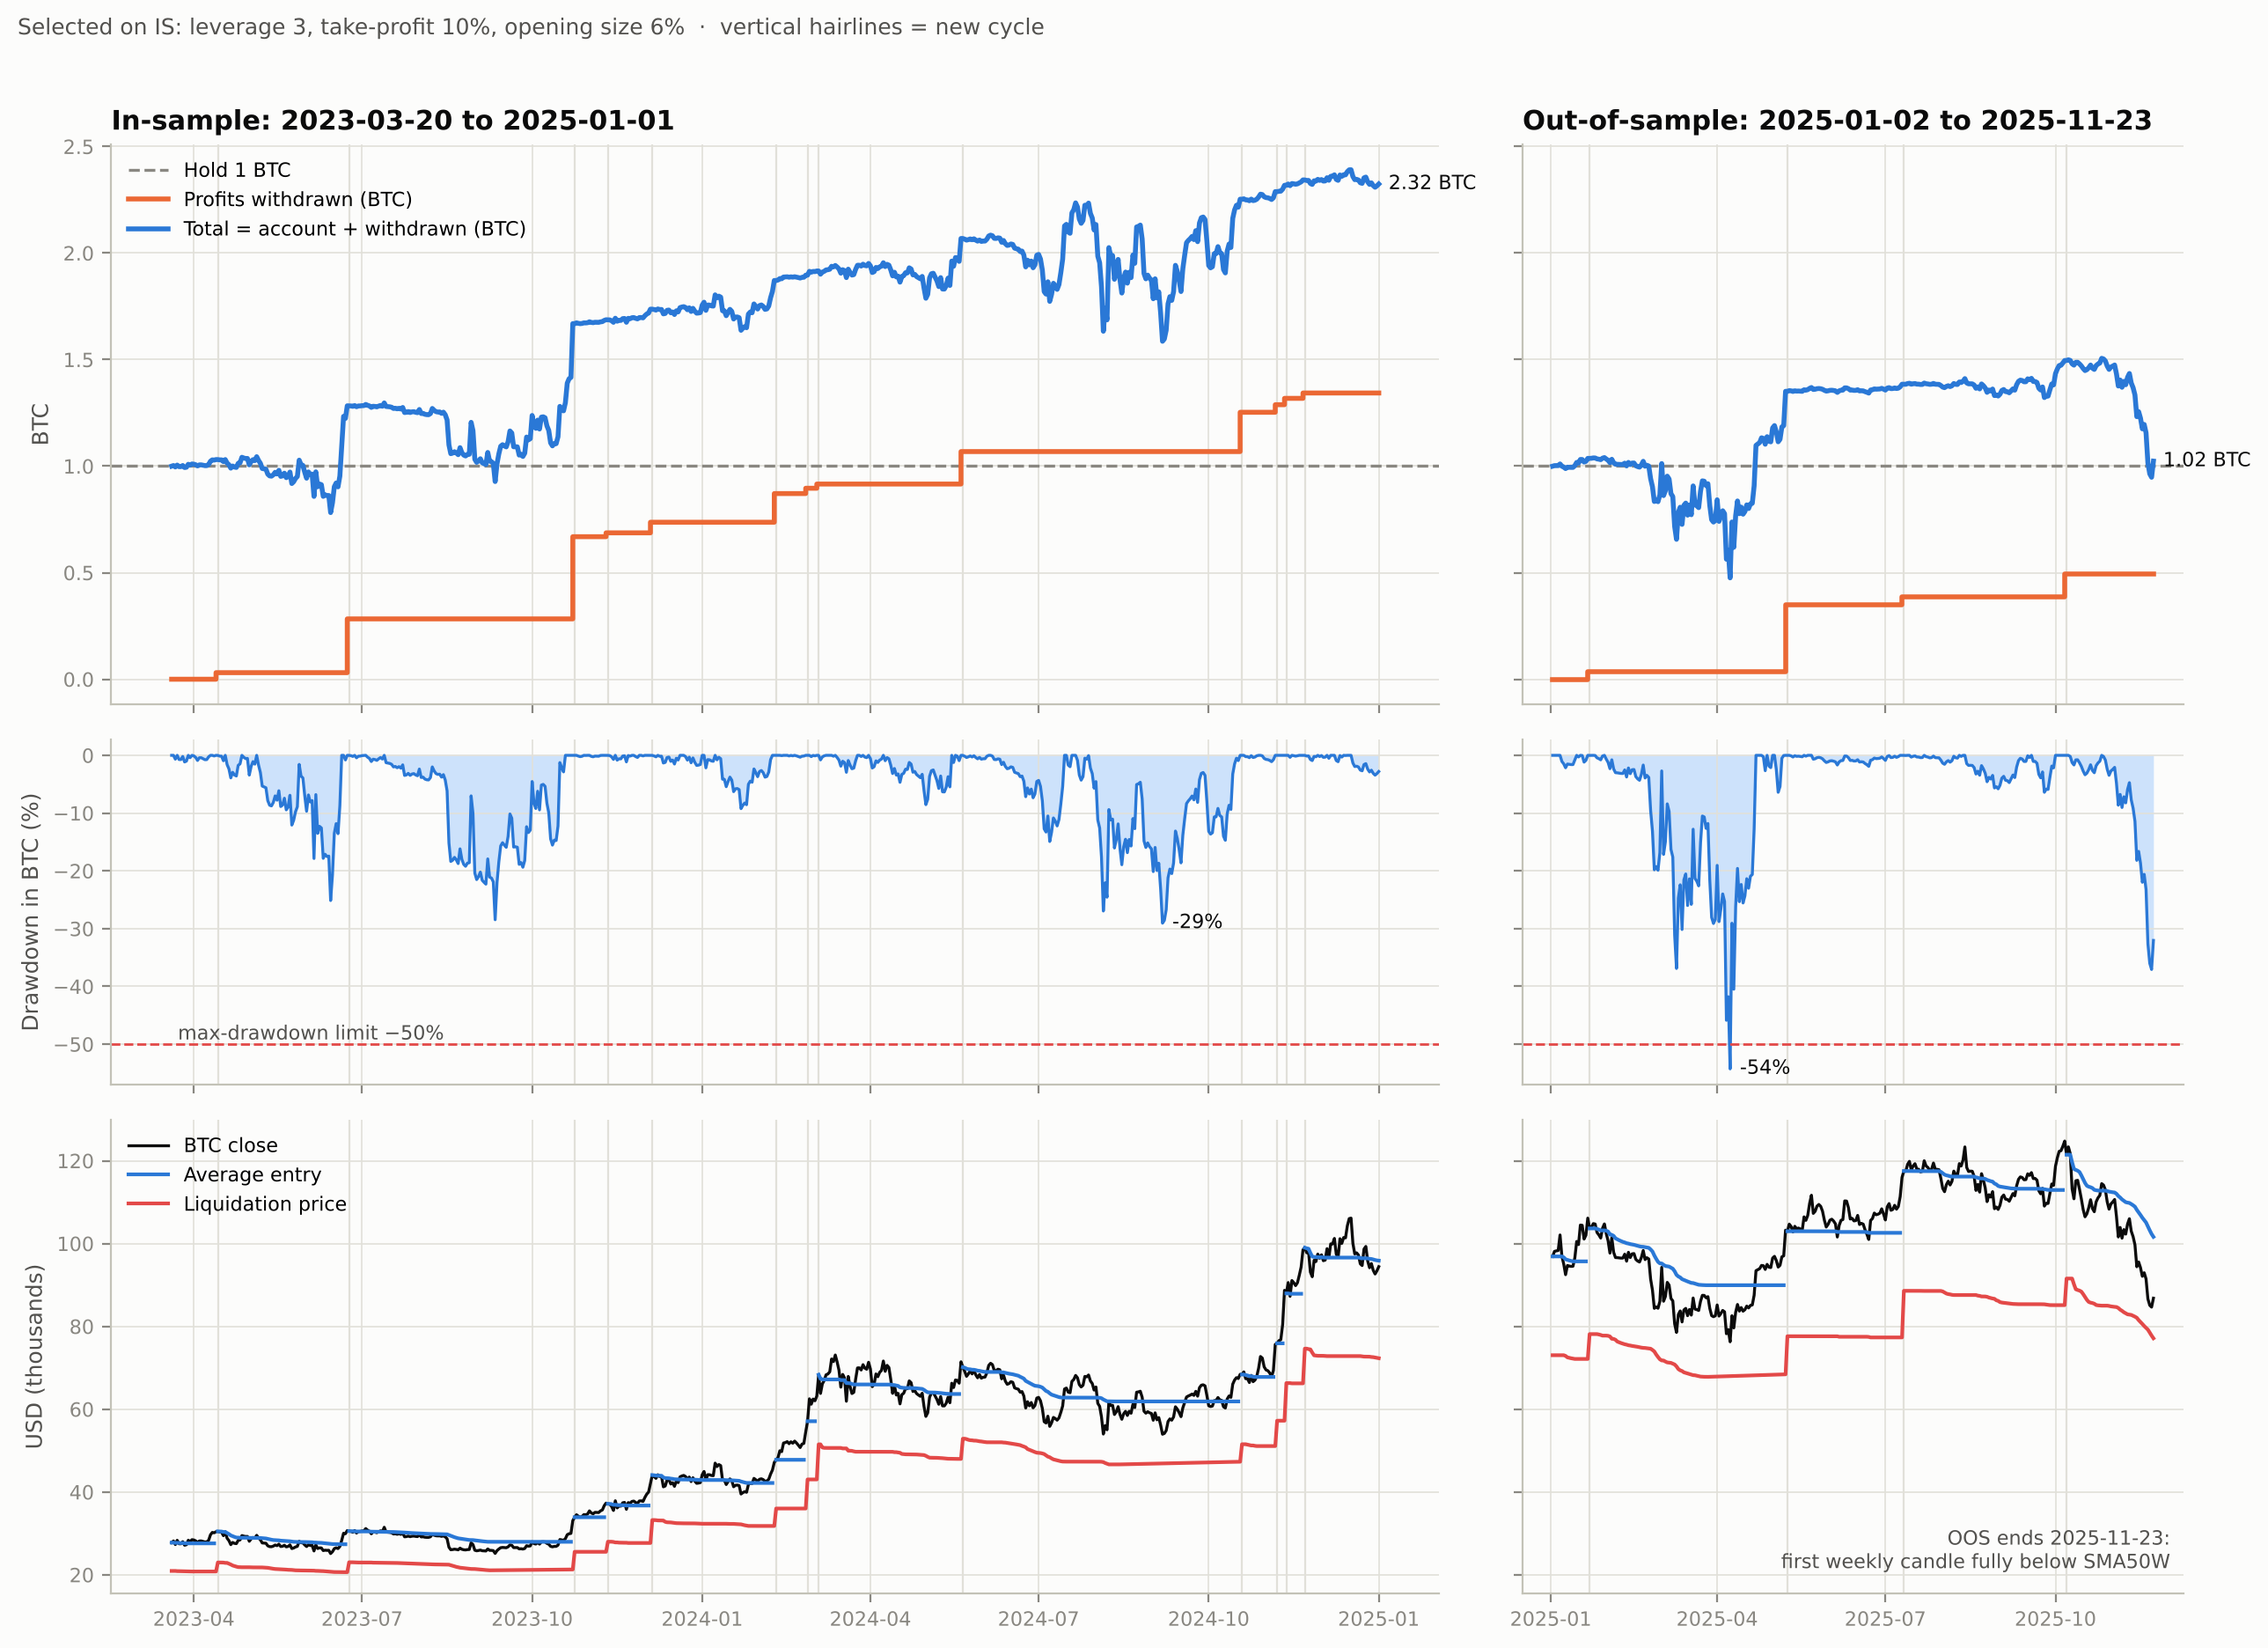

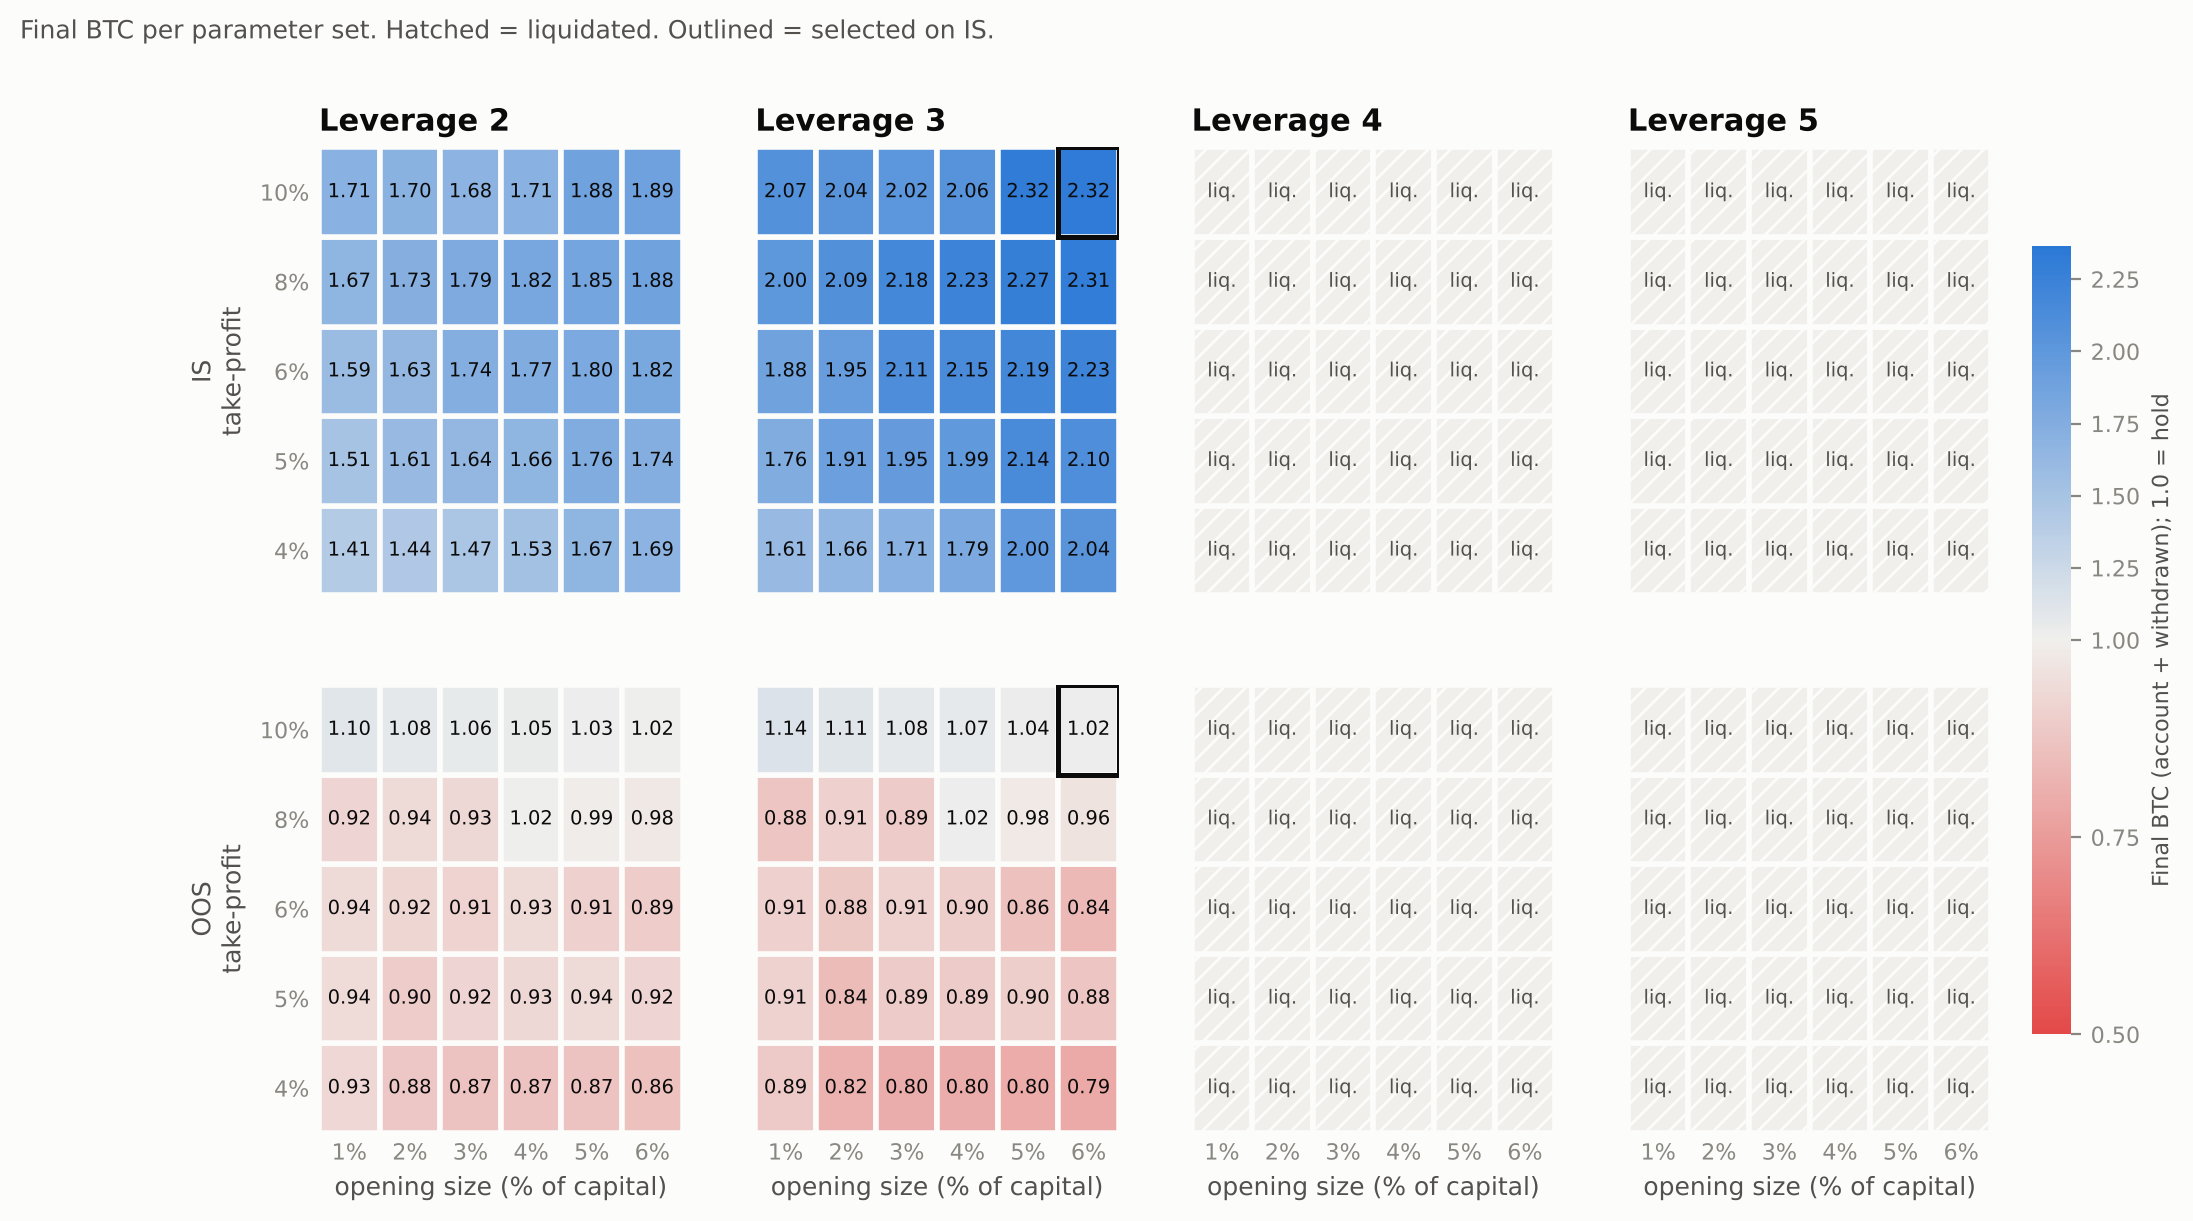

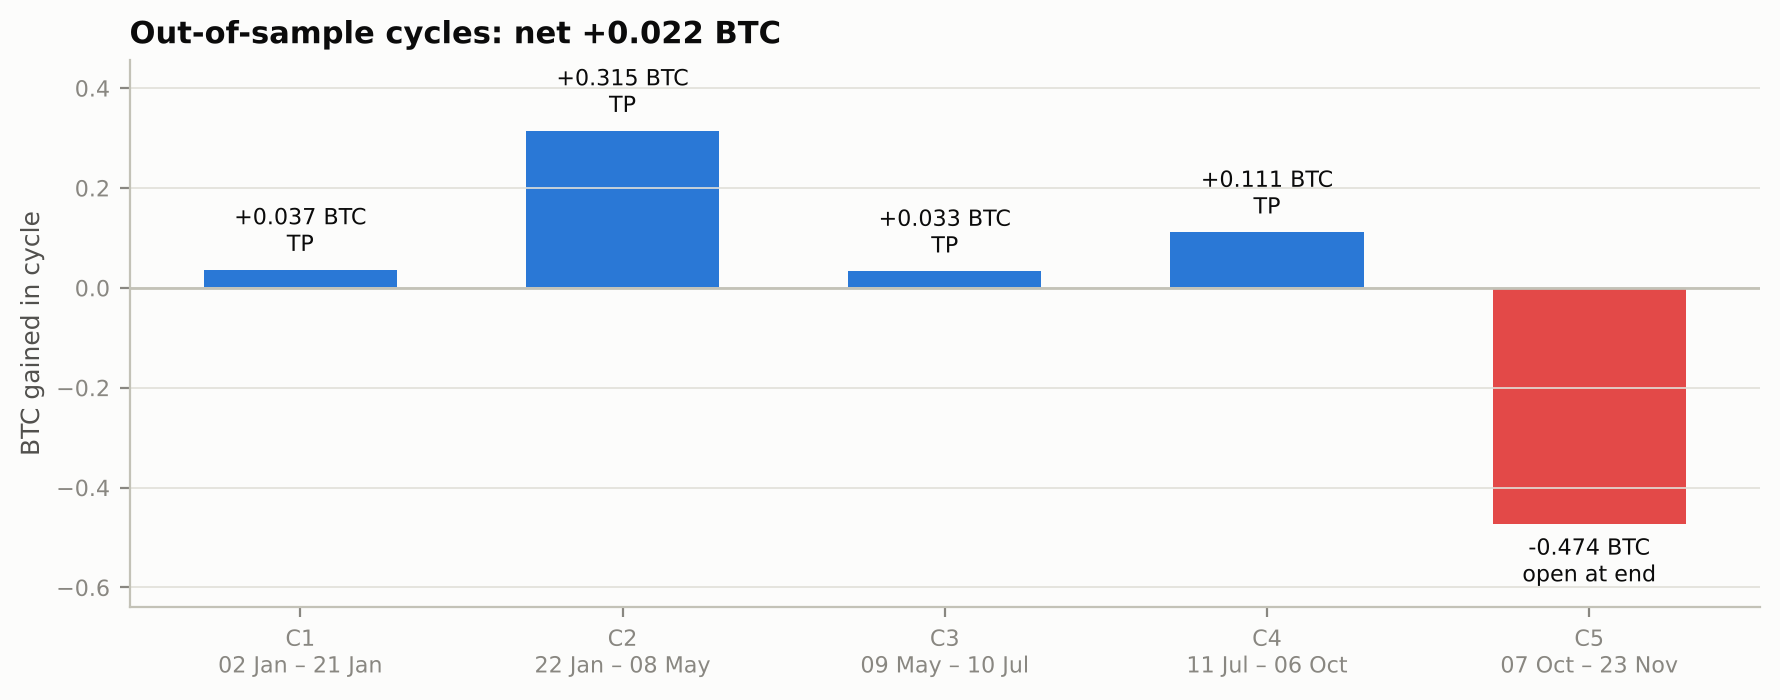

In [9]:
import os
os.makedirs('results', exist_ok=True)
grid_is.to_csv('results/grid_is.csv', index=False)
grid_oos.to_csv('results/grid_oos.csv', index=False)
cycles_oos.to_csv('results/cycles_oos.csv', index=False)
table.to_csv('results/summary_selected.csv')

plots.equity_figure(res_is['perf'], res_is['cycles'], res_oos['perf'], res_oos['cycles'],
                    best, 'figures/equity_btc.png')
plots.grid_figure(grid_is, grid_oos, best, 'figures/grid_final_btc.png')
plots.cycles_figure(res_oos['cycles'], 'figures/oos_cycles.png')
plt.show()

## 9. Limitations

- Daily bars: liquidation is checked against the daily low; intraday path and gaps are approximated.
- Close-based fills.
- Constant funding (10% p.a.); real funding varies and was higher in strong bull phases.
- Simplified isolated-margin liquidation formula; exchange rules (risk tiers, insurance fund, ADL) are not modelled.
- One IS window (~21 months) and one OOS window (~11 months), both in a single market regime.